# Time Series Similarity Search — Practice lab

Data Acquisition, Extraction and Storage — M2 (PSL)

**Name(s):** BORDERIES

**Personal seed $u_0$:** 462358

### How to use this notebook
* The subject (PDF) contains the definitions and the full statements. This notebook follows its structure.
* **Questions Q** (numerical): compute the four items a)–d) and store them in the variables `Q1`, `Q2`, ... (lists of 4 values). They are gathered in the dictionary `ANSWERS` at the end of the notebook.
* **Questions T** (theory / experiments): answer in the Markdown cells marked *Your answer*. Proofs, short algorithm descriptions, complexities, plots + comments. Do not paste your code there.
* **Allowed:** Python standard library, `numpy`, `matplotlib`. **Not allowed:** any library computing the requested distances / representations / indexes for you (`scipy.spatial`, `sklearn.neighbors`, `tslearn`, `sktime`, `aeon`, `pyts`, `dtaidistance`, `fastdtw`, `stumpy`, `rtree`, `faiss`, ...).
* **Work first with `SEED = 42`** and compare with the reference sheet (the function `check_reference()` at the end does it for you). Then set `SEED` to your personal seed, re-run everything, and keep the notebook in that state.
* Real-valued answers: rounded to 2 decimals. Counting questions: strict inequalities.


Use of AI to help me write in english and in markdown

In [155]:
import math, time, heapq, bisect, itertools
from collections import deque
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import unicodedata

def seed_from_name(family_name: str) -> int:
    """Deterministic personal seed in [1, 10^6] computed from a family name (DO NOT MODIFY)."""
    s = unicodedata.normalize("NFKD", family_name)
    s = "".join(c for c in s if c.isalpha() and not unicodedata.combining(c)).lower()
    h = int.from_bytes(hashlib.sha256(s.encode("utf-8")).digest()[:8], "big")
    seed = 1 + h % 1_000_000
    return seed if seed != 42 else 43          # 42 is reserved for the reference sheet


SEED = seed_from_name("BORDERIES")



## 1. Preliminaries — the dataset
The cell below is the generator (Appendix A of the subject). **Do not modify it.**

In [156]:
import numpy as np

# ---------------------------------------------------------------------------
# Pseudo-random generator: DO NOT MODIFY (it defines your personal dataset)
# ---------------------------------------------------------------------------
MOD = 2 ** 31
A, C = 1103515245, 12345


class LCG:
    """Tiny linear congruential generator, identical on every platform."""

    def __init__(self, seed):
        self.state = seed % MOD
        for _ in range(8):                      # warm-up
            self.next()

    def next(self):
        self.state = (A * self.state + C) % MOD
        return self.state

    def randint(self, a, b):
        """Uniform integer in [a, b] (both included)."""
        return a + (self.next() >> 16) % (b - a + 1)


def _rng(seed, tag, k):
    return LCG(seed * 1_000_003 + tag * 7_919 + k * 104_729 + 1)


def _walk(rng, l):
    """Integer-valued signal: slow random walk + 1 to 3 rectangular bumps."""
    x = rng.randint(-10, 10)
    t = [0] * l
    for i in range(l):
        t[i] = x
        if rng.randint(0, 3) == 0:
            x += rng.randint(-1, 1) * 2
    for _ in range(rng.randint(1, 3)):
        h = rng.randint(8, 15) * (1 if rng.randint(0, 1) else -1)
        w = rng.randint(max(1, l // 32), max(1, l // 16))
        p = rng.randint(0, l - w)
        for i in range(p, p + w):
            t[i] += h
    return t


def series(seed, k, l):
    """The series T_k of length l (a numpy array of integers)."""
    return np.array(_walk(_rng(seed, 0, k), l), dtype=np.int64)


def database(seed, n=1000, l=256):
    """The database D = [T_0, ..., T_{n-1}] as an (n, l) numpy array of integers."""
    return np.stack([series(seed, k, l) for k in range(n)])


QUERY_TYPES = [(0, 1), (0, 4), (10, 1), None]   # (max. warping, noise); None = new series


def query(seed, j, D):
    """The query Q_j (j in {0, 1, 2, 3}), of the same length as the series of D."""
    n, l = D.shape
    rng = _rng(seed, 1, j)
    qt = QUERY_TYPES[j % 4]
    if qt is None:
        return np.array(_walk(rng, l), dtype=np.int64)
    warp, noise = qt
    src = D[rng.randint(0, n - 1)]
    s, mode, q = 0, 1, [0] * l
    for i in range(l):
        if i > 0:
            if rng.randint(0, 7) == 0:          # change of warping regime
                mode = rng.randint(0, 2)        # 0: stretch, 1: none, 2: compress
            step = mode if rng.randint(0, 1) == 0 else 1
            s = min(max(s + step, i - warp), i + warp, s + 2, l - 1)
        q[i] = int(src[s]) + rng.randint(-noise, noise)
    return np.array(q, dtype=np.int64)

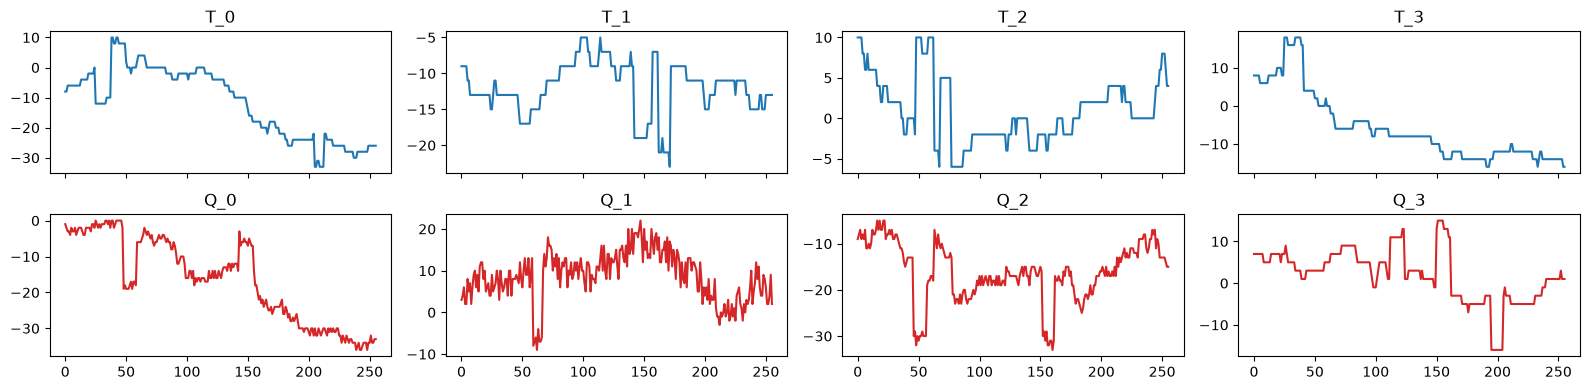

In [157]:
D = database(SEED)                      # D[k] is T_k, shape (1000, 256)
n, l = D.shape
Qs = [query(SEED, j, D) for j in range(4)]

fig, ax = plt.subplots(2, 4, figsize=(16, 4), sharex=True)
for j in range(4):
    ax[0, j].plot(D[j]); ax[0, j].set_title(f"T_{j}")
    ax[1, j].plot(Qs[j], c="C3"); ax[1, j].set_title(f"Q_{j}")
plt.tight_layout(); plt.show()

**Q1** — amplitude $\max_i t_i - \min_i t_i$ of $T_0, T_1, T_{500}, T_{999}$.

In [158]:
# Amplitude de chaque série : valeur maximale moins valeur minimale.
Q1 = [int(D[k].max() - D[k].min()) for k in (0, 1, 500, 999)]
print("Q1", Q1)

Q1 [43, 18, 14, 32]


---
## 2. Euclidean distance, PAA and lower-bounding search *(in class)*

In [159]:
def ed(a, b):
    """Euclidean distance between two series of the same length."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(np.sqrt(np.sum((a - b) ** 2)))

Q2 = [round(ed(D[i], D[j]), 2) for i, j in ((0, 1), (10, 20), (100, 200), (998, 999))]
print("Q2", Q2)

Q2 [187.81, 108.52, 255.57, 221.03]


In [160]:
def paa(T, N):
    """PAA of order N of T (N divides len(T))."""
    T = np.asarray(T, dtype=float)
    if N <= 0 or len(T) % N != 0:
        raise ValueError("N doesn't divide len(T)")
    return T.reshape(N, len(T) // N).mean(axis=1)

def dr(Ta_paa, Tb_paa, l):
    """Distance DR between two PAA representations of series of length l."""
    N = len(Ta_paa)
    return float(np.sqrt(l / N) * ed(Ta_paa, Tb_paa))

Q3 = [round(dr(paa(D[0], N), paa(D[1], N), l), 2) for N in (4, 16, 64, 256)]
print("Q3", Q3)

Q3 [158.9, 175.15, 184.21, 187.81]


**T1** — Prove that $\mathsf{DR}\le\mathsf{ED}$.

*Your answer:*

# Proof: DR is a lower bound of ED

We want to prove that, for all $T_a,T_b\in\mathbb{R}^l$,

$$
DR(\widetilde T_a,\widetilde T_b)\leq ED(T_a,T_b).
$$

Let $T_a=(x_1,\ldots,x_l)$ and $T_b=(y_1,\ldots,y_l)$.

We use the PAA representation with $N$ segments of equal length $m=l/N$. The approximate distance is defined by

$$
DR(\widetilde T_a,\widetilde T_b)
=\sqrt{\frac{l}{N}\sum_{j=1}^{N}(\bar x_j-\bar y_j)^2},
$$

where $\bar x_j$ and $\bar y_j$ are the means of the values in segment $j$.

## 1. Proof for one segment ($N=1$)

Let $\mu_a$ and $\mu_b$ be the means of $T_a$ and $T_b$.

We want to prove that

$$
\sum_{i=1}^{l}(x_i-y_i)^2\geq l(\mu_a-\mu_b)^2.
$$

We can write each point as

$$
x_i=\mu_a-\Delta x_i,\qquad
y_i=\mu_b-\Delta y_i.
$$

Thus,

$$
\begin{aligned}
\sum_{i=1}^{l}(x_i-y_i)^2
&=\sum_{i=1}^{l}\left[(\mu_a-\mu_b)-(\Delta x_i-\Delta y_i)\right]^2\\
&=l(\mu_a-\mu_b)^2\\
&\quad-2(\mu_a-\mu_b)\sum_{i=1}^{l}(\Delta x_i-\Delta y_i)\\
&\quad+\sum_{i=1}^{l}(\Delta x_i-\Delta y_i)^2.
\end{aligned}
$$

By definition of the means,

$$
\sum_{i=1}^{l}\Delta x_i
=l\mu_a-\sum_{i=1}^{l}x_i=0,
$$

and similarly,

$$
\sum_{i=1}^{l}\Delta y_i=0.
$$

Therefore,

$$
\sum_{i=1}^{l}(\Delta x_i-\Delta y_i)=0.
$$

The cross term vanishes, so

$$
\sum_{i=1}^{l}(x_i-y_i)^2
=l(\mu_a-\mu_b)^2
+\sum_{i=1}^{l}(\Delta x_i-\Delta y_i)^2.
$$

Since the last term is nonnegative,

$$
\boxed{
\sum_{i=1}^{l}(x_i-y_i)^2
\geq l(\mu_a-\mu_b)^2
}
$$

Hence, for one segment,

$$
ED(T_a,T_b)\geq DR(\widetilde T_a,\widetilde T_b).
$$

## 2. Generalization to $N$ segments

Let $T_a^{(j)}$ and $T_b^{(j)}$ denote the subsequences corresponding to segment $j$, each of length $m=l/N$.

The squared Euclidean distance can be decomposed as

$$
ED(T_a,T_b)^2
=\sum_{j=1}^{N}ED(T_a^{(j)},T_b^{(j)})^2.
$$

Using the result proved for one segment, we have, for every $j$,

$$
ED(T_a^{(j)},T_b^{(j)})^2
\geq m(\bar x_j-\bar y_j)^2.
$$

Summing over all segments gives

$$
\begin{aligned}
ED(T_a,T_b)^2
&\geq \sum_{j=1}^{N}m(\bar x_j-\bar y_j)^2\\
&=\frac{l}{N}\sum_{j=1}^{N}(\bar x_j-\bar y_j)^2\\
&=DR(\widetilde T_a,\widetilde T_b)^2.
\end{aligned}
$$

Both distances being nonnegative, taking the square root yields

$$
\boxed{
\forall T_a,T_b\in\mathbb R^l,\quad
DR(\widetilde T_a,\widetilde T_b)\leq ED(T_a,T_b).
}
$$

Thus, **DR is a lower bound of the Euclidean distance ED**.

**T2** — Compare $\mathsf{DR}$ with orders $N \mid N'$. What is $\mathsf{DR}$ when $N=l$?

*Your answer:*


### Proof that $DR_N \leq DR_{N'}$ when $N\mid N'$

Let $k=N'/N$. Each of the $N$ segments can be divided into $k$ subsegments.

From the previous result, the squared distance between the means of a segment, multiplied by its length, is lower than the sum of squared differences over its $k$ subsegments, each weighted by its length.

Thus, for every segment $j$,

$$
\frac{l}{N}(\bar x_j-\bar y_j)^2
\leq
\frac{l}{N'}\sum_{r=1}^{k}
(\bar x_{j,r}-\bar y_{j,r})^2.
$$

Summing over the $N$ segments gives

$$
DR_N^2\leq DR_{N'}^2.
$$

Since distances are nonnegative,

$$
\boxed{DR_N\leq DR_{N'}\leq ED(T_a,T_b).}
$$

When $N=l$, each segment contains exactly one point, so

$$
\boxed{DR_l=ED(T_a,T_b).}
$$


In [161]:
# Q4: brute-force nearest neighbour under ED -> list of (k, distance)
Q4 = []
for Q in Qs:
    # Comparer la requête à toutes les séries de la base.
    distances = [ed(Q, T) for T in D]
    k = int(np.argmin(distances))
    Q4.append((k, round(distances[k], 2)))

print("Q4", Q4)

Q4 [(225, 13.42), (696, 40.11), (405, 91.03), (17, 69.18)]


**T3** — Algorithm `findNN` using the PAA (best case $O(nN+l)$), correctness, worst-case complexity, when does the best case happen?

*Your answer:*

### T3 — Algorithm findNN

1. Precompute the PAA representations of all database series.
2. Compute the PAA representation of the query $Q$ and the DR distances to all database series.
3. Select the series with the smallest DR and compute its exact ED. Initialize the best candidate and best distance.
4. For each remaining series, if its DR is smaller than the current best ED, compute its exact ED and update the best candidate if necessary.
5. Return the best candidate and its ED.

it never misses the NN because DR is a lower bond of ED, therefore if we have a candidate, his DR must be smaller than our best ED and therefore we'll have to look for his ED. Also, the worst case complexity is O(nN+nl) = O(nl) which append in case when the ED and DR are in opposite order, the best case happen when the smallest ED also have the smallest DR.

In [162]:
def find_nn(Q, D, D_paa, N):
    """Exact nearest neighbour of Q under ED using the PAA lower bound.
    Suggested return value: (index, distance, number of exact ED computations)."""
    Q_paa = paa(Q, N)
    lower_bounds = [dr(Q_paa, T_paa, len(Q)) for T_paa in D_paa]

    # Initialiser avec la série dont la borne DR est la plus petite.
    first_k = int(np.argmin(lower_bounds))
    best_k = first_k
    best_distance = ed(Q, D[best_k])
    n_ed = 1

    for k, lower_bound in enumerate(lower_bounds):
        if k != first_k and lower_bound < best_distance:
            distance = ed(Q, D[k])
            n_ed += 1
            if distance < best_distance:
                best_k = k
                best_distance = distance

    return best_k, best_distance, n_ed

# Compter les séries autres que NN dont DR est strictement inférieur à ED(Q, NN).
Q5 = []
for j, N in ((2, 4), (3, 2), (3, 4), (3, 8)):
    Q = Qs[j]
    D_paa = np.array([paa(T, N) for T in D])
    k_nn, distance_nn, _ = find_nn(Q, D, D_paa, N)
    Q_paa = paa(Q, N)
    count = sum(
        k != k_nn and dr(Q_paa, T_paa, len(Q)) < distance_nn
        for k, T_paa in enumerate(D_paa)
    )
    Q5.append(count)
print("Q5", Q5)

Q5 [55, 137, 81, 20]


**T4** *(experiment)* — Link between Q5 and the number of exact computations of `findNN`; plots of the number of exact ED computations and of the running time as functions of $N\in\{2,4,\dots,128\}$; comparison with brute force; comment.

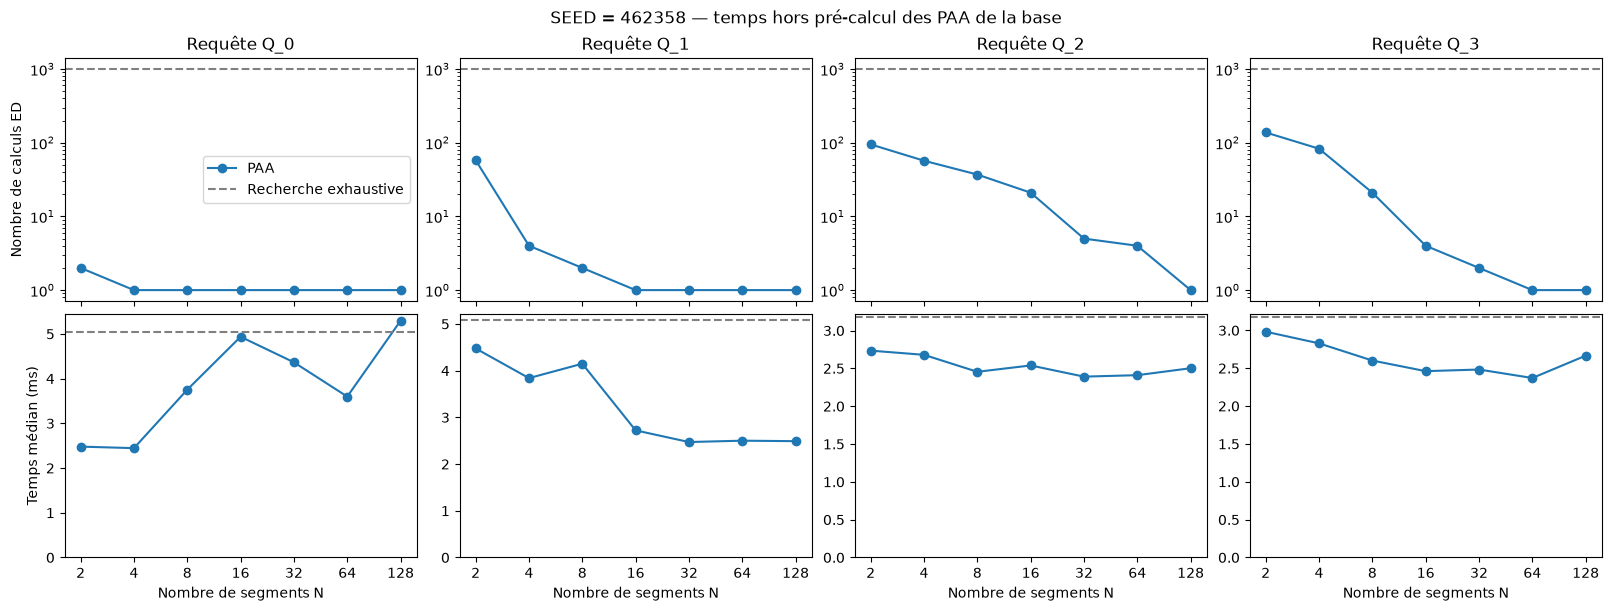

Lien avec Q5 :
Q_2, N=4 : minimum = 56, ED calculées = 57
Q_3, N=2 : minimum = 138, ED calculées = 138
Q_3, N=4 : minimum = 82, ED calculées = 83
Q_3, N=8 : minimum = 21, ED calculées = 21


In [163]:
from timeit import repeat

def median_ms(fn):
    fn()  # Premier appel hors mesure.
    return 1000 * float(np.median(repeat(fn, number=1, repeat=5)))

# Mesurer les recherches pour chaque requête et chaque ordre N.
Ns = [2, 4, 8, 16, 32, 64, 128]
PAA_DATABASES = {N: D.reshape(n, N, l // N).mean(axis=2) for N in Ns}
ed_counts = np.zeros((4, len(Ns)), dtype=int)
nn_times_ms = np.zeros_like(ed_counts, dtype=float)
brute_times_ms = []

for j, Q in enumerate(Qs):
    brute_times_ms.append(median_ms(lambda: np.argmin([ed(Q, T) for T in D])))
    for h, N in enumerate(Ns):
        ed_counts[j, h] = find_nn(Q, D, PAA_DATABASES[N], N)[2]
        nn_times_ms[j, h] = median_ms(lambda: find_nn(Q, D, PAA_DATABASES[N], N))

# Comparer les nombres de calculs et les temps.
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True, constrained_layout=True)
for j in range(4):
    axes[0, j].plot(Ns, ed_counts[j], "o-", label="PAA")
    axes[0, j].axhline(n, color="gray", ls="--", label="Recherche exhaustive")
    axes[0, j].set_title(f"Requête Q_{j}")
    axes[0, j].set_yscale("log")
    axes[1, j].plot(Ns, nn_times_ms[j], "o-")
    axes[1, j].axhline(brute_times_ms[j], color="gray", ls="--")
    axes[1, j].set_ylim(bottom=0)
    axes[1, j].set_xlabel("Nombre de segments N")
    for ax in axes[:, j]:
        ax.set_xscale("log", base=2)
        ax.set_xticks(Ns, labels=Ns)
axes[0, 0].set_ylabel("Nombre de calculs ED")
axes[1, 0].set_ylabel("Temps médian (ms)")
axes[0, 0].legend()
fig.suptitle(f"SEED = {SEED} — temps hors pré-calcul des PAA de la base")
plt.show()

print("Lien avec Q5 :")
for count, (j, N) in zip(Q5, [(2, 4), (3, 2), (3, 4), (3, 8)]):
    print(f"Q_{j}, N={N} : minimum = {count + 1}, ED calculées = {ed_counts[j, Ns.index(N)]}")

Let $c$ be the count in Q5 and $d_*$ the true nearest-neighbour distance. Every non-NN with a lower bound below $d_*$ must be evaluated, since the current best distance is always at least $d_*$. Including the NN itself gives at least $c+1$ exact ED computations. Additional candidates may be evaluated before the best threshold is found.

With `SEED = 462358`:

| Query | $N$ | Q5 + 1 | Actual ED computations |
|---|---:|---:|---:|
| $Q_2$ | 4 | 56 | 57 |
| $Q_3$ | 2 | 138 | 138 |
| $Q_3$ | 4 | 82 | 83 |
| $Q_3$ | 8 | 21 | 21 |

Increasing $N$ tightens the PAA bounds. Here the ED counts decrease for all four queries: for $Q_2$, from 95 at $N=2$ to 1 at $N=128$, versus 1000 for brute force. This monotonic behaviour is an observation, not a general guarantee for this scan order.

The measured query times are roughly 2.3–3.0 ms for PAA search and 2.8–3.1 ms for brute force. Computing the $n$ bounds costs $O(nN)$, so avoiding exact ED calls does not yield a proportional speed-up. Times are medians of five runs after a warm-up; database PAA construction is excluded because it is reused across queries.

---
## 3. Dynamic Time Warping *(in class)*

**T5** — Worst-case complexity of the trivial algorithm enumerating all admissible paths.

*Your answer:*



### T5 — Complexity of brute-force DTW

For two time series of equal length $l$, consider the transitions from $(i,i)$ to $(i+1,i+1)$. Each transition has at least two possible admissible paths: one diagonal step or two successive steps (horizontal then vertical).

Since these choices are independent for the $l-1$ transitions, the number of admissible paths satisfies

$$
|\mathcal A(T_a,T_b)|\geq 2^{l-1}.
$$

Therefore, enumerating all admissible paths has **exponential worst-case time complexity**:

$$
\boxed{\Omega(2^l)}
$$



**T6** — A polynomial algorithm for DTW: description, correctness, time and memory complexities. Can the memory be reduced if only the distance is needed?

*Your answer:*


### T6 — Dynamic Programming Algorithm for DTW

We define $D(i,j)$ as the minimum squared cost of an admissible warping path ending at $(i,j)$.

**Initialization:**

$$
D(0,0)=(a_0-b_0)^2
$$

with $D(i,j)=+\infty$ for indices outside the matrix.

**Recurrence:**

$$
D(i,j)=(a_i-b_j)^2+
\min\begin{cases}
D(i-1,j),\\
D(i,j-1),\\
D(i-1,j-1).
\end{cases}
$$

**Algorithm:**
1. Initialize a matrix $D$ of size $l_a\times l_b$.
2. Fill it using the recurrence, from top-left to bottom-right.
3. Return $\sqrt{D(l_a-1,l_b-1)}$.

**Correctness:** Every admissible path ending at $(i,j)$ must come from one of the three preceding cells. By choosing the minimum cost at each cell, dynamic programming computes the optimal path cost.

**Complexities:**
- **Time:** $O(l_a l_b)$, since each cell is computed in constant time.
- **Memory:** $O(l_a l_b)$ to store the entire matrix.

If only the distance is needed, each row depends only on the previous row and the current row. Thus, memory can be reduced to

$$
\boxed{O(\min(l_a,l_b))}
$$

while keeping the time complexity $O(l_a l_b)$.


In [164]:
def dtw(a, b):
    """DTW distance between two series of any lengths."""
    if len(a) < len(b):
        a, b = b, a  # Garder la série la plus courte en colonnes.
    previous = [float("inf")] * (len(b) + 1)
    previous[0] = 0.0

    for x in a:
        x = float(x)
        current = [float("inf")] * (len(b) + 1)
        for j, y in enumerate(b, start=1):
            cost = (x - float(y)) ** 2
            current[j] = cost + min(previous[j], current[j - 1], previous[j - 1])
        previous = current

    return math.sqrt(previous[-1])

# pairs: (T_1^(50), T_2^(60)), (T_10^(300), T_20^(200)), (T_30^(1000), T_40^(1500)), (T_50^(3000), T_60^(3000))
# T_k^(l) is series(SEED, k, l)
q6_pairs = [((1, 50), (2, 60)), ((10, 300), (20, 200)),
            ((30, 1000), (40, 1500)), ((50, 3000), (60, 3000))]
Q6 = [
    round(dtw(series(SEED, ka, la), series(SEED, kb, lb)), 2)
    for (ka, la), (kb, lb) in q6_pairs
]
print("Q6", Q6)

Q6 [67.62, 77.92, 293.15, 1712.55]


**T7** — Is DTW a metric? Counter-examples, and why it matters for similarity search.

*Your answer:*

### T7 — Is DTW a metric?

**No, DTW is not a metric.** Although it is nonnegative and symmetric, it does not satisfy the triangle inequality.

**Triangle inequality**

Consider $A=[0,0]$, $B=[0]$ and $C=[1]$.

We have

$$
DTW(A,B)=0,\quad DTW(B,C)=1,
$$

but

$$
DTW(A,C)=\sqrt{2}>0+1.
$$

Thus,

$$
DTW(A,C)>DTW(A,B)+DTW(B,C).
$$

**Consequences for similarity search:** Since DTW does not satisfy the triangle inequality, metric-based indexing and pruning methods relying on this property cannot be directly applied. Instead, we can use specific lower bounds of DTW to safely eliminate candidates.



**T8** — A lower bound of DTW (any lengths) computable in $O(1)$; proof.

*Your answer:*

### T8 — A lower bound for DTW in O(1)

By the boundary conditions of DTW, every admissible warping path must contain both $(0,0)$ and $(l_a-1,l_b-1)$.

Therefore, for $(l_a,l_b)\neq(1,1)$, we can define

$$
LB(T_a,T_b)=\sqrt{(a_0-b_0)^2+(a_{l_a-1}-b_{l_b-1})^2}.
$$

If $l_a=l_b=1$, we simply use $LB(T_a,T_b)=|a_0-b_0|$.

**Proof:** Since every admissible path contains these endpoint pairs and all squared costs are nonnegative, its total cost is at least the sum of their squared costs. Thus,

$$
\boxed{LB(T_a,T_b)\leq DTW(T_a,T_b).}
$$

**Complexity:** $O(1)$, since only the first and last elements of each series are needed. No preprocessing is required.


In [165]:
def lb_dtw(a, b):
    """O(1) lower bound of DTW for two non-empty series."""
    first = float(a[0]) - float(b[0])
    if len(a) == len(b) == 1:
        return abs(first)  # Le premier et le dernier couple sont identiques.
    last = float(a[-1]) - float(b[-1])
    return math.sqrt(first ** 2 + last ** 2)


# Vérifier la borne sur des séries aléatoires, de longueurs égales ou différentes.
rng_t8 = np.random.default_rng(SEED)
for la, lb in [(1, 1), (1, 20), (20, 1), (10, 10), (15, 30), (30, 15)]:
    for _ in range(50):
        a = rng_t8.integers(-20, 21, size=la)
        b = rng_t8.integers(-20, 21, size=lb)
        assert lb_dtw(a, b) <= dtw(a, b) + 1e-10

print("T8 : LB <= DTW vérifié sur 300 paires aléatoires.")

T8 : LB <= DTW vérifié sur 300 paires aléatoires.


**T9** — $\mathsf{DTW}_0$, $\mathsf{DTW}_{l-1}$, monotonicity in $w$, ordering between ED, $\mathsf{DTW}_w$ and DTW, complexities of your $\mathsf{DTW}_w$.

*Your answer:*

### T9 — Constrained DTW (Sakoe–Chiba Band)

**1. Extreme cases**

- **$w=0$:** Only diagonal alignments ($i=j$) are allowed, so

$$
\boxed{DTW_0(T_a,T_b)=ED(T_a,T_b).}
$$

- **$w=l-1$:** Every admissible path is allowed, so

$$
\boxed{DTW_{l-1}(T_a,T_b)=DTW(T_a,T_b).}
$$

**2. Monotonicity**

For $w_1\leq w_2$, every path admissible for $w_1$ is also admissible for $w_2$. Thus, minimizing over a larger set of paths cannot increase the distance:

$$
DTW_{w_2}(T_a,T_b)\leq DTW_{w_1}(T_a,T_b).
$$

Therefore,

$$
\boxed{DTW\leq DTW_w\leq ED.}
$$

**3. Complexity**

Using dynamic programming, we only compute cells satisfying $|i-j|\leq w$.

- **Time:** $O(l(w+1))$, since there are at most $l(2w+1)$ cells to compute.
- **Memory:** $O(l(w+1))$ to store the band and reconstruct the optimal path.
- **Optimized memory:** $O(w+1)$ if only the distance is needed, since each row depends only on the previous row and the current row.


In [166]:
def dtw_w(a, b, w):
    """DTW constrained by a Sakoe-Chiba band of width w (series of the same length)."""
    if len(a) != len(b) or w < 0:
        raise ValueError("Les séries doivent avoir la même longueur et w doit être positif ou nul.")
    inf = float("inf")
    previous = {0: 0.0}

    for i, x in enumerate(a, start=1):
        x = float(x)
        current = {}  # Ne stocker que les colonnes de la bande.
        for j in range(max(1, i - w), min(len(b), i + w) + 1):
            cost = (x - float(b[j - 1])) ** 2
            current[j] = cost + min(
                previous.get(j, inf), current.get(j - 1, inf), previous.get(j - 1, inf)
            )
        previous = current

    return math.sqrt(previous[len(b)])

# (T0, T1, w=0), (T0, T1, w=10), (T0, T1, w=255), (T_5^(1e5), T_6^(1e5), w=20)
Q7 = [round(dtw_w(D[0], D[1], w), 2) for w in (0, 10, 255)]
Q7.append(round(dtw_w(series(SEED, 5, 100_000), series(SEED, 6, 100_000), 20), 2))
print("Q7", Q7)

Q7 [187.81, 178.6, 134.48, 33865.68]


In [167]:
# Q8: nearest neighbour under DTW_w -> list of (k, distance) for (Q_1, w=10), (Q_2, w=10), (Q_3, w=10), (Q_2, w=5)
Q8 = []
for j, w in [(1, 10), (2, 10), (3, 10), (2, 5)]:
    distances = [dtw_w(Qs[j], T, w) for T in D]
    k = int(np.argmin(distances))
    Q8.append((k, round(distances[k], 2)))
print("Q8", Q8)

Q8 [(696, 36.51), (399, 13.45), (17, 56.11), (399, 53.21)]


**T10** *(experiment)* — For the four queries ($w=10$): NN under ED (Q4) vs under $\mathsf{DTW}_w$; ratio 2nd-NN / NN distance under ED and under $\mathsf{DTW}_w$; interpretation (look at how the queries are generated). What changes for $Q_2$ with $w=5$?

In [168]:
# Compare the two nearest neighbours and their distance ratio.
t10_results = []
for j, Q in enumerate(Qs):
    metrics = [("ED", None), ("DTW_10", 10)]
    if j == 2:
        metrics.append(("DTW_5", 5))
    for metric, w in metrics:
        distances = np.array([ed(Q, T) if w is None else dtw_w(Q, T, w) for T in D])
        k1, k2 = np.argsort(distances, kind="stable")[:2]
        d1, d2 = distances[k1], distances[k2]
        ratio = d2 / d1 if d1 > 0 else np.nan
        t10_results.append((j, metric, int(k1), float(d1), int(k2), float(d2), float(ratio)))

print(f"{'Query':<7}{'Distance':<10}{'NN':>6}{'d1':>10}{'2nd NN':>8}{'d2':>10}{'d2/d1':>9}")
for j, metric, k1, d1, k2, d2, ratio in t10_results:
    print(f"Q_{j:<5}{metric:<10}{k1:6d}{d1:10.2f}{k2:8d}{d2:10.2f}{ratio:9.2f}")

# Recover the source indices using the same first draw as query().
source_indices = [_rng(SEED, 1, j).randint(0, len(D) - 1) for j in range(3)]
print("Sources of Q_0, Q_1, Q_2:", source_indices)

Query  Distance      NN        d1  2nd NN        d2    d2/d1
Q_0    ED           225     13.42     176     90.75     6.76
Q_0    DTW_10       225     13.42     378     71.08     5.30
Q_1    ED           696     40.11     900     87.99     2.19
Q_1    DTW_10       696     36.51     716     62.28     1.71
Q_2    ED           405     91.03       7     92.68     1.02
Q_2    DTW_10       399     13.45     561     72.63     5.40
Q_2    DTW_5        399     53.21     405     81.50     1.53
Q_3    ED            17     69.18     915     84.42     1.22
Q_3    DTW_10        17     56.11     915     63.38     1.13
Sources of Q_0, Q_1, Q_2: [225, 696, 399]


The ratio $r=d_2/d_1$ measures how clearly the nearest neighbour stands out: values close to 1 indicate nearly tied candidates.

With `SEED = 462358`:

- **$Q_0$ and $Q_1$** are noisy copies of $T_{225}$ and $T_{696}$, without time warping. ED and $\mathrm{DTW}_{10}$ both recover these sources. Their ratios decrease from 6.76 to 5.30 and from 2.19 to 1.71, respectively: warping also helps competing series.
- **$Q_2$** is a warped, slightly noisy copy of $T_{399}$. ED selects $T_{405}$ with distance 91.03 and $r=1.018$. $\mathrm{DTW}_{10}$ recovers $T_{399}$ with distance 13.45 and $r=5.398$, making the source much easier to distinguish.
- **$Q_3$** is generated independently. Both distances select $T_{17}$, with ratios 1.22 under ED and 1.13 under $\mathrm{DTW}_{10}$: the match is less clearly separated than the noisy copies.

For **$Q_2$ with $w=5$**, the NN remains $T_{399}$, but its distance rises to 53.21 and the ratio falls to 1.532. The narrower band restricts the allowed alignment: the source is still retrieved, but with much less separation than at $w=10$.

---
## 4. Adaptive Piecewise Constant Approximation *(at home)*

**T11** — $\mathsf{Err}(s,T)$ in $O(1)$ after $O(l)$ pre-processing; numerical issues and how to avoid them.

*Your answer:*

### T11 — Computing segment errors in O(1)

We precompute two prefix sums in $O(l)$:

$$
S_k=\sum_{i=0}^{k-1}t_i,\qquad
Q_k=\sum_{i=0}^{k-1}t_i^2.
$$

For a segment $[b,e]$ of length $m=e-b+1$, its mean is

$$
\mu=\frac{S_{e+1}-S_b}{m}.
$$

Expanding the squared error gives:

$$
\begin{aligned}
Err(s,T)
&=\sum_{i=b}^{e}(t_i-\mu)^2\\
&=\sum_{i=b}^{e}t_i^2-m\mu^2\\
&=\boxed{Q_{e+1}-Q_b-\frac{(S_{e+1}-S_b)^2}{m}}.
\end{aligned}
$$

**Complexity and numerical issues:**

Two prefix arrays take $O(l)$ time and memory; each segment error then takes $O(1)$ arithmetic operations.

Subtracting large, nearly equal floating-point quantities can cause precision loss or produce small negative errors. Fixed-width integers can also overflow when computing $mh$ or $s^2$, even if the prefix sums fit.

To avoid these issues, we can use Python integers and compare rational costs exactly, using

$$
\boxed{m\cdot Err(s,T)=mh-s^2}
$$

where $h=Q_{e+1}-Q_b$ and $s=S_{e+1}-S_b$.

For Q9 and bottom-up APCA, I use exact arithmetic. For Q11, the DP uses float64 for efficiency, and the selected partition's error is recomputed exactly. However, floating-point rounding during the DP may theoretically affect the optimality of the selected partition.



In [169]:
def compute_minimal_cost(T, ls):
    """Returns (b_min, minimal error) over length-ls segments of an integer series."""
    if not 1 <= ls <= len(T):
        raise ValueError("ls doit être compris entre 1 et len(T).")
    s = sum(int(x) for x in T[:ls])
    h = sum(int(x) ** 2 for x in T[:ls])
    best_b, best_cost = 0, ls * h - s * s

    for b in range(1, len(T) - ls + 1):
        # Retirer le point sortant et ajouter le point entrant.
        old, new = int(T[b - 1]), int(T[b + ls - 1])
        s += new - old
        h += new * new - old * old
        cost = ls * h - s * s  # ls * Err : comparaison exacte en entiers.
        if cost < best_cost:
            best_b, best_cost = b, cost

    return best_b, best_cost / ls

# (T_0^(1e3), 50), (T_5^(1e4), 500), (T_10^(1e5), 5000), (T_20^(1e6), 1e4) -> list of (b_min, Err)
Q9 = []
for k, length, ls in [(0, 1000, 50), (5, 10_000, 500),
                      (10, 100_000, 5000), (20, 1_000_000, 10_000)]:
    b, error = compute_minimal_cost(series(SEED, k, length), ls)
    Q9.append((b, round(error, 2)))
print("Q9", Q9)

Q9 [(550, 42.32), (5047, 3587.2), (87825, 243740.02), (670654, 1201608.49)]


In [170]:
def bu_apca(T, N):
    """Bottom-up APCA with N segments; exact merge costs, ties to the left."""
    length = len(T)
    if not 1 <= N <= length:
        raise ValueError("N doit être compris entre 1 et len(T).")

    # Sommes préfixes en entiers Python : coût exact d'un segment en O(1).
    sums, squares = [0], [0]
    for x in T:
        x = int(x)
        sums.append(sums[-1] + x)
        squares.append(squares[-1] + x * x)

    def error(b, e):
        m = e - b + 1
        s = sums[e + 1] - sums[b]
        h = squares[e + 1] - squares[b]
        return Fraction(m * h - s * s, m)

    # Un segment par point ; left/right relient les segments voisins.
    ends = {i: i for i in range(length)}
    left = list(range(-1, length - 1))
    right = list(range(1, length + 1))
    heap = [(error(i, i + 1), i, i + 1, i + 1) for i in range(length - 1)]
    heapq.heapify(heap)

    while len(ends) > N:
        _, b, split, e = heapq.heappop(heap)
        # Ignorer les coûts devenus obsolètes après une fusion.
        if ends.get(b) != split - 1 or ends.get(split) != e:
            continue
        ends[b] = e
        del ends[split]
        right[b] = right[split]
        if right[b] < length:
            left[right[b]] = b

        # Seules les deux paires voisines ont un nouveau coût.
        for start in (left[b], b):
            if start >= 0 and right[start] < length:
                middle = right[start]
                end = ends[middle]
                heapq.heappush(heap, (error(start, end), start, middle, end))

    return sorted(ends.items())


# (longest segment, total error)
Q10 = []
for k, length, N in [(0, 1000, 10), (5, 10_000, 20),
                     (10, 20_000, 50), (20, 100_000, 100)]:
    T = series(SEED, k, length)
    segments = bu_apca(T, N)
    total_error = Fraction(0)
    for b, e in segments:
        values = [int(x) for x in T[b:e + 1]]
        m, s, h = len(values), sum(values), sum(x * x for x in values)
        total_error += Fraction(m * h - s * s, m)
    longest = max(e - b + 1 for b, e in segments)
    Q10.append((longest, float(round(total_error, 2))))
print("Q10", Q10)

Q10 [(146, 6346.17), (1282, 208550.25), (922, 392393.34), (3116, 4959845.12)]


**T12** — Complexity of a straightforward `BuAPCA`; strategy for $O(l\log l)$.

*Your answer:*

### T12 — Complexity of Bottom-Up APCA

**1. Straightforward implementation**

Starting with $l$ segments, we repeatedly compute the merging costs of all adjacent pairs, select the minimum, and merge them until only $N$ segments remain.

Using the $O(1)$ segment error computation from T11, each iteration costs $O(k)$ for $k$ remaining segments.

Thus, the worst-case time complexity is

$$
\boxed{O(l^2)}
$$

**2. Optimized implementation: $O(l\log l)$**

We use:
- A **min-heap** storing the merging costs of adjacent segments, with the leftmost index as a tie-breaker.
- A **doubly linked list** to maintain adjacent segments.
- Prefix sums to compute merging costs in $O(1)$.

At each iteration:
1. Extract the pair with minimum cost from the heap.
2. Merge the two segments and update their neighbours.
3. Recompute and insert only the affected merging costs, invalidating obsolete entries.

There are $O(l)$ merges, each requiring $O(\log l)$ heap operations.

Therefore,

$$
\boxed{\text{Time: }O(l\log l),\qquad \text{Memory: }O(l)}
$$

Costs are compared using exact rational arithmetic to ensure correct merging decisions and tie-breaking.




**T13** — Algorithm for the optimal APCA, justification, complexities; comparison with the enumeration of all segmentations.

*Your answer:*

### T13 — Optimal APCA using Dynamic Programming

We define $DP[k,j]$ as the minimum error for approximating the first $j$ points of a series using exactly $k$ segments.

**Initialization:**

$$
DP[0,0]=0,
$$

with all other invalid states initialized to $+\infty$.

**Recurrence:**

$$
\boxed{
DP[k,j]=\min_{k-1\leq i<j}
\left(DP[k-1,i]+Err([i,j-1],T)\right)
}
$$

**Algorithm:**
1. Precompute prefix sums to evaluate segment errors in $O(1)$.
2. Fill the DP table using the recurrence.
3. Return $DP[N,l]$ and reconstruct the optimal segmentation by backtracking the minimizing indices.

**Correctness:** Any optimal segmentation of the first $j$ points into $k$ segments has a final segment $[i,j-1]$. The preceding $k-1$ segments must themselves form an optimal segmentation of the first $i$ points. The recurrence considers every possible $i$, ensuring global optimality.

**Complexities:**
- **Time:** $O(Nl^2)$, since each DP state considers up to $l$ possible split points.
- **Memory:** $O(Nl)$ for the DP table and backtracking, reducible to $O(l)$ if only the optimal error is needed.

**Comparison with brute force:**

There are

$$
\binom{l-1}{N-1}
$$

possible segmentations, since we must choose $N-1$ boundaries among $l-1$ positions.

Evaluating each segmentation takes $O(N)$ using prefix sums, giving

$$
\boxed{O\left(N\binom{l-1}{N-1}\right)}
$$

which is combinatorial, whereas dynamic programming is polynomial.


In [171]:
def optimal_apca(T, N):
    """Optimal APCA of an integer series. Returns (segments, total error)."""
    length = len(T)
    if not 1 <= N <= length:
        raise ValueError("N doit être compris entre 1 et len(T).")

    # Centrer les valeurs limite les pertes de précision dans les coûts.
    x = np.array([int(t) - int(T[0]) for t in T], dtype=float)
    sums = np.concatenate(([0.0], np.cumsum(x)))
    squares = np.concatenate(([0.0], np.cumsum(x * x)))
    dp = np.full((N + 1, length + 1), np.inf)
    cuts = np.zeros((N + 1, length + 1), dtype=int)
    dp[0, 0] = 0.0

    # dp[k, j] : erreur minimale pour les j premiers points en k segments.
    for k in range(1, N + 1):
        for j in range(k, length + 1):
            starts = np.arange(k - 1, j)
            s = sums[j] - sums[starts]
            errors = squares[j] - squares[starts] - s * s / (j - starts)
            costs = dp[k - 1, starts] + np.maximum(errors, 0.0)
            best = int(np.argmin(costs))
            dp[k, j] = costs[best]
            cuts[k, j] = starts[best]

    # Reconstruire la partition à partir des coupures retenues.
    segments, end = [], length
    for k in range(N, 0, -1):
        start = int(cuts[k, end])
        segments.append((start, end - 1))
        end = start
    segments.reverse()

    # La DP utilise des flottants ; recalculer exactement l'erreur finale.
    total_error = Fraction(0)
    for b, e in segments:
        values = [int(t) for t in T[b:e + 1]]
        m, s, h = len(values), sum(values), sum(t * t for t in values)
        total_error += Fraction(m * h - s * s, m)
    return segments, float(total_error)


# (T_0^(200), 5), (T_5^(500), 10), (T_10^(1000), 10), (T_20^(2000), 8)
Q11 = [
    round(optimal_apca(series(SEED, k, length), N)[1], 2)
    for k, length, N in [(0, 200, 5), (5, 500, 10), (10, 1000, 10), (20, 2000, 8)]
]
print("Q11", Q11)

Q11 [2143.56, 1821.04, 9435.67, 23620.04]


In [172]:
# T14: compare bottom-up APCA with the optimal errors from Q11.
t14_results = []
for case, (k, length, N) in enumerate([(0, 200, 5), (5, 500, 10),
                                      (10, 1000, 10), (20, 2000, 8)]):
    T = series(SEED, k, length)
    total_error = Fraction(0)
    for b, e in bu_apca(T, N):
        values = [int(x) for x in T[b:e + 1]]
        total_error += sum(x * x for x in values) - Fraction(sum(values) ** 2, len(values))
    t14_results.append((Q11[case], float(round(total_error, 2))))
print("Case | optimal error | bottom-up error")
for case, (optimal, greedy) in zip("abcd", t14_results):
    print(f"{case} | {optimal:.2f} | {greedy:.2f}")

Case | optimal error | bottom-up error
a | 2143.56 | 2481.86
b | 1821.04 | 2099.36
c | 9435.67 | 11629.87
d | 23620.04 | 26783.25


**T14** — Is `BuAPCA` optimal? Smallest counter-example; comparison on the series of Q11.

*Your answer:*


### T14 — Is Bottom-Up APCA optimal?

**No, BuAPCA is not always optimal**, since its greedy merging decisions do not necessarily minimize the final total error.

**Smallest counterexample:**

Consider $T=[0,1,0,1]$ with $N=2$.

- **BuAPCA:** The leftmost pair is merged first (all initial merging costs are equal). The final segmentation is $[0,1]\mid[0,1]$, with total error:

$$
Err_{\text{BuAPCA}}=\frac12+\frac12=1.
$$

- **Optimal APCA:** The segmentation $[0]\mid[1,0,1]$ gives:

$$
Err_{\text{optimal}}=0+\frac23=\frac23.
$$

Therefore,

$$
\boxed{Err_{\text{BuAPCA}}=1>\frac23=Err_{\text{optimal}}.}
$$

This is a minimal counterexample: for $l\leq3$, the greedy algorithm is always optimal.

**Comparison on Q11:**

With `SEED = 462358`, the computed errors are:

| Case | Optimal APCA error | BuAPCA error |
|---|---:|---:|
| a) | 2143.56 | 2481.86 |
| b) | 1821.04 | 2099.36 |
| c) | 9435.67 | 11629.87 |
| d) | 23620.04 | 26783.25 |

BuAPCA has a strictly larger error in all four cases. It is faster ($O(l\log l)$), but unlike the dynamic programming algorithm ($O(Nl^2)$), it does not guarantee optimality.


**T15** — Prove $\mathsf{LB\_APCA}\le\mathsf{ED}$; complexity for the whole database.

*Your answer:*

### T15 — Lower Bound of APCA

We want to prove that

$$
LB_{APCA}(Q,T)\leq ED(Q,T).
$$

Let $S_i=[b_i,e_i]$ be a segment of length $m_i=e_i-b_i+1$, with means $\bar q_i$ and $x_i$ for $Q$ and $T$ respectively.

By Cauchy–Schwarz,

$$
\begin{aligned}
\sum_{j=b_i}^{e_i}(q_j-t_j)^2
&\geq \frac{1}{m_i}\left(\sum_{j=b_i}^{e_i}(q_j-t_j)\right)^2\\
&=m_i(\bar q_i-x_i)^2.
\end{aligned}
$$

Summing over all $N$ segments,

$$
\begin{aligned}
ED(Q,T)^2
&=\sum_{i=0}^{N-1}\sum_{j=b_i}^{e_i}(q_j-t_j)^2\\
&\geq\sum_{i=0}^{N-1}m_i(\bar q_i-x_i)^2\\
&=LB_{APCA}(Q,T)^2.
\end{aligned}
$$

Therefore,

$$
\boxed{LB_{APCA}(Q,T)\leq ED(Q,T).}
$$

**Complexity:**

Assuming the APCA representations of the database are precomputed:

- Compute prefix sums of $Q$ in $O(l)$.
- Compute each segment mean in $O(1)$, giving $O(N)$ per series.
- For $n$ series, the total complexity is

$$
\boxed{O(l+nN)}
$$

instead of $O(nl)$ for computing all exact Euclidean distances.


In [173]:
def lb_apca(Q, T_apca, Q_prefix=None):
    """Lower bound of ED(Q, T); T_apca contains (b, e, mean) with inclusive bounds.
    Q_prefix optionally supplies precomputed prefix sums of Q.
    """
    if Q_prefix is None:
        Q_prefix = np.concatenate(([0.0], np.cumsum(Q, dtype=float)))
    squared_lb = 0.0
    for b, e, mean in T_apca:
        m = e - b + 1
        q_mean = (Q_prefix[e + 1] - Q_prefix[b]) / m
        squared_lb += m * (q_mean - mean) ** 2
    return math.sqrt(squared_lb)


# Pré-calculer les APCA de la base : (début, fin, moyenne) par segment.
D_apca = {}
for N in (4, 8):
    D_apca[N] = [
        [(b, e, float(np.mean(T[b:e + 1]))) for b, e in bu_apca(T, N)]
        for T in D
    ]

# Compter les candidats, sans le vrai NN, avec une inégalité stricte.
Q12 = []
for j, N in [(2, 4), (2, 8), (3, 4), (3, 8)]:
    nn = Q4[j][0]
    distance_nn = ed(Qs[j], D[nn])  # Ne pas utiliser la distance arrondie de Q4.
    Q_prefix = np.concatenate(([0.0], np.cumsum(Qs[j], dtype=float)))
    count = sum(
        k != nn and lb_apca(Qs[j], T_apca, Q_prefix) < distance_nn
        for k, T_apca in enumerate(D_apca[N])
    )
    Q12.append(count)
print("Q12", Q12)

Q12 [45, 25, 48, 6]


**T16** *(experiment)* — APCA ($N=8$) vs PAA ($N=16$): reconstruction error, number of candidates, tightness. Does a better approximation always lead to a better pruning? Explain.

In [174]:
# Compare APCA(8) and PAA(16) using the database representations from Q12.
D_paa16 = D.reshape(n, 16, l // 16).mean(axis=2)
paa_errors = np.sum((D - np.repeat(D_paa16, l // 16, axis=1)) ** 2, axis=1)
apca_errors = np.array([
    sum(np.sum((T[b:e + 1] - mean) ** 2) for b, e, mean in representation)
    for T, representation in zip(D, D_apca[8])
])
print(f"Mean reconstruction error: PAA(16) = {paa_errors.mean():.2f}, APCA(8) = {apca_errors.mean():.2f}")

t16_results = []
print(f"{'Query':<7}{'Method':<10}{'Candidates':>12}{'Mean LB/ED':>14}")
for j, Q in enumerate(Qs):
    distances = np.array([ed(Q, T) for T in D])
    nn = int(np.argmin(distances))
    Q_paa = paa(Q, 16)
    Q_prefix = np.concatenate(([0.0], np.cumsum(Q, dtype=float)))
    bounds = {
        "PAA(16)": np.array([dr(Q_paa, T_paa, l) for T_paa in D_paa16]),
        "APCA(8)": np.array([lb_apca(Q, representation, Q_prefix) for representation in D_apca[8]])
    }
    for method, lower_bounds in bounds.items():
        # Strict inequality, exclude NN; tightness excludes zero ED distances.
        count = int(np.sum((lower_bounds < distances[nn]) & (np.arange(n) != nn)))
        nonzero = distances > 0
        tightness = float(np.mean(lower_bounds[nonzero] / distances[nonzero]))
        t16_results.append((j, method, count, tightness))
        print(f"Q_{j:<5}{method:<10}{count:12d}{tightness:14.3f}")


Mean reconstruction error: PAA(16) = 1833.85, APCA(8) = 673.67
Query  Method      Candidates    Mean LB/ED
Q_0    PAA(16)              0         0.975
Q_0    APCA(8)              0         0.958
Q_1    PAA(16)              0         0.913
Q_1    APCA(8)              0         0.914
Q_2    PAA(16)             16         0.949
Q_2    APCA(8)             25         0.938
Q_3    PAA(16)              3         0.923
Q_3    APCA(8)              6         0.900


With `SEED = 462358`, APCA(8) has a much lower mean reconstruction error than PAA(16): **673.67 versus 1833.85** (sum of squared errors per series).

| Query | Candidates PAA / APCA | Mean tightness PAA / APCA |
|---|---:|---:|
| $Q_0$ | 0 / 0 | 0.975 / 0.958 |
| $Q_1$ | 0 / 0 | 0.913 / 0.914 |
| $Q_2$ | 16 / 25 | 0.949 / 0.938 |
| $Q_3$ | 3 / 6 | 0.923 / 0.900 |

Candidate counts exclude the true NN and use the strict condition $LB(Q,T)<ED(Q,NN)$. Tightness is the mean of $LB/ED$ over series with nonzero ED; values closer to 1 indicate tighter bounds.

**Better reconstruction does not imply better pruning.** Despite its lower reconstruction error, APCA leaves more candidates for both $Q_2$ and $Q_3$. Its boundaries are chosen to approximate $T$, whereas pruning depends on how the segment means distinguish $Q$ from $T$. The partitions are not nested, so neither bound universally dominates the other. Mean tightness alone also does not determine the candidate count, which depends on bounds relative to the NN distance.

---
## 5. Lower bounding DTW and indexing with an R-tree *(at home)*

**T17** — Prove $\mathsf{LB\_Keogh}\le\mathsf{DTW}_w$.

*Your answer:*

### T17 — Proof that LB_Keogh is a lower bound of DTW

We want to prove that

$$
LB_{Keogh}(Q,C)\leq DTW_w(Q,C).
$$

By definition of the envelope,

$$
L_i=\min_{|j-i|\leq w}q_j,\qquad
U_i=\max_{|j-i|\leq w}q_j,
$$

where $j$ is restricted to valid indices.

For any admissible warping path $\pi$, each point $c_i$ is matched with at least one $q_j$ satisfying $|i-j|\leq w$. Therefore, $q_j\in[L_i,U_i]$, and

$$
(c_i-q_j)^2\geq
\begin{cases}
(c_i-U_i)^2 & \text{if }c_i>U_i,\\
(c_i-L_i)^2 & \text{if }c_i<L_i,\\
0 & \text{otherwise}.
\end{cases}
$$

Since every index $i$ appears at least once in $\pi$, summing these lower bounds gives

$$
\sum_{(i,j)\in\pi}(c_i-q_j)^2
\geq LB_{Keogh}(Q,C)^2.
$$

This holds for every admissible path. Taking the minimum over all paths and then the square root yields

$$
\boxed{LB_{Keogh}(Q,C)\leq DTW_w(Q,C).}
$$



**T18** — Complexity of the naive envelope; an $O(l)$ algorithm.

*Your answer:*

### T18 — Computing the Envelope Efficiently

**Naive approach:**

For each index $i$, compute the minimum and maximum over the window $[\max(0,i-w),\min(l-1,i+w)]$.

Each window requires $O(w+1)$ operations, giving a total complexity of

$$
\boxed{O(l\min(l,2w+1))}
$$

**Optimized approach: $O(l)$**

We use two **monotonic deques** to maintain the minimum and maximum of the sliding window:

1. Move the right boundary forward and insert new indices, removing elements from the back that cannot become the minimum (respectively maximum).
2. Remove indices from the front when they leave the window.
3. The front of each deque gives $L_i$ and $U_i$ in $O(1)$.

Each index is inserted and removed at most once from each deque, so the total complexity is

$$
\boxed{\text{Time: }O(l),\qquad \text{Auxiliary memory: }O(\min(l,w+1))}
$$

The time complexity is independent of $w$.


In [175]:
def envelope(Q, w):
    """Returns (U, L), the envelope of Q for a band w, in O(len(Q))."""
    if w < 0:
        raise ValueError("w doit être positif ou nul.")
    U, L = np.empty(len(Q)), np.empty(len(Q))
    minima, maxima = deque(), deque()
    right = 0
    for i in range(len(Q)):
        # Ajouter les nouveaux points à droite de la fenêtre.
        while right < min(len(Q), i + w + 1):
            while minima and Q[minima[-1]] >= Q[right]:
                minima.pop()
            while maxima and Q[maxima[-1]] <= Q[right]:
                maxima.pop()
            minima.append(right)
            maxima.append(right)
            right += 1
        # Retirer les indices sortis à gauche.
        while minima and minima[0] < i - w:
            minima.popleft()
        while maxima and maxima[0] < i - w:
            maxima.popleft()
        U[i], L[i] = Q[maxima[0]], Q[minima[0]]
    return U, L


def lb_keogh(Q, C, w, Q_envelope=None):
    """LB_Keogh using the envelope of Q; optionally reuse a precomputed envelope."""
    U, L = envelope(Q, w) if Q_envelope is None else Q_envelope
    C = np.asarray(C, dtype=float)
    return float(np.sqrt(np.sum((C - np.clip(C, L, U)) ** 2)))


Q13 = [round(lb_keogh(Qs[j], D[j], 10), 2) for j in range(4)]

Q14 = []
for j, w in [(1, 10), (3, 10), (1, 20), (3, 20)]:
    distances = [dtw_w(Qs[j], T, w) for T in D]
    nn = int(np.argmin(distances))
    Q_envelope = envelope(Qs[j], w)
    count = sum(
        k != nn and lb_keogh(Qs[j], T, w, Q_envelope) < distances[nn]
        for k, T in enumerate(D)
    )
    Q14.append(count)
print("Q13", Q13)
print("Q14", Q14)

Q13 [83.82, 254.42, 208.68, 117.33]
Q14 [23, 51, 89, 124]


**T19** *(experiment)* — Tightness $\mathsf{LB\_Keogh}/\mathsf{DTW}_w$ as a function of $w$.

Q_2 versus its source T_399, SEED = 462358
    w    LB_Keogh       DTW_w      LB/DTW
    0       94.04       94.04       1.000
    1       78.77       86.97       0.906
    2       67.79       79.01       0.858
    3       56.80       70.87       0.801
    5       34.12       53.21       0.641
    8       16.31       32.82       0.497
   10        2.24       13.45       0.166
   15        2.00       13.45       0.149
   20        2.00       13.45       0.149
   30        2.00       13.45       0.149
   50        0.00       13.45       0.000
  100        0.00       13.45       0.000
  255        0.00       13.45       0.000


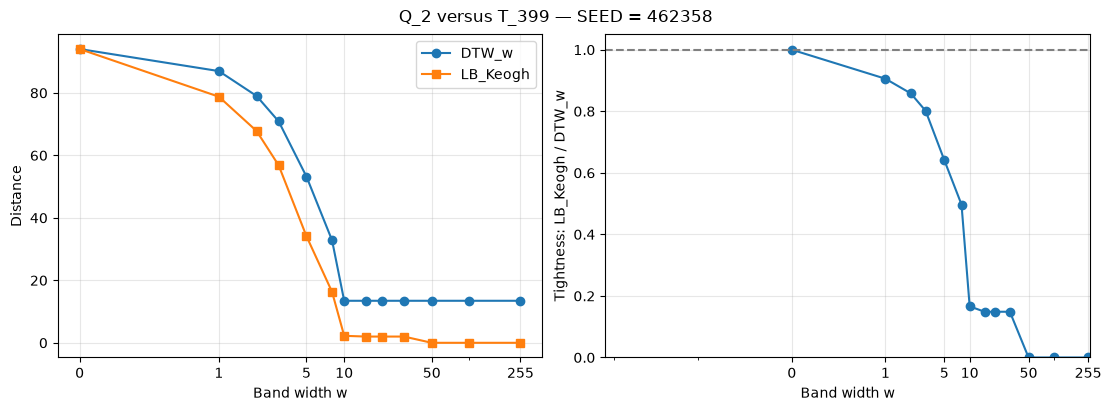

In [176]:
# Keep the same query and candidate while changing the band width.
j = 2
k = _rng(SEED, 1, j).randint(0, len(D) - 1)  # Source used to generate Q_2.
Q, C = Qs[j], D[k]
widths = [0, 1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 100, len(Q) - 1]
values = np.array([(lb_keogh(Q, C, w), dtw_w(Q, C, w)) for w in widths])
lower_bounds, distances = values.T
tightness = np.divide(lower_bounds, distances, out=np.full(len(widths), np.nan),
                      where=distances > 0)

print(f"Q_{j} versus its source T_{k}, SEED = {SEED}")
print(f"{'w':>5}{'LB_Keogh':>12}{'DTW_w':>12}{'LB/DTW':>12}")
for w, lb, distance, ratio in zip(widths, lower_bounds, distances, tightness):
    print(f"{w:5d}{lb:12.2f}{distance:12.2f}{ratio:12.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(widths, distances, "o-", label="DTW_w")
axes[0].plot(widths, lower_bounds, "s-", label="LB_Keogh")
axes[0].set_ylabel("Distance")
axes[0].legend()
axes[1].plot(widths, tightness, "o-")
axes[1].axhline(1, color="gray", ls="--")
axes[1].set_ylabel("Tightness: LB_Keogh / DTW_w")
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.set_xscale("symlog", linthresh=1)
    ax.set_xticks([0, 1, 5, 10, 50, len(Q) - 1], labels=[0, 1, 5, 10, 50, len(Q) - 1])
    ax.set_xlabel("Band width w")
    ax.grid(True, alpha=0.3)
fig.suptitle(f"Q_{j} versus T_{k} — SEED = {SEED}")
plt.show()

We fix $Q_2$ and its source $T_{399}$ (`SEED = 462358`) and use the same $w$ for the envelope and DTW. The ratio $LB_{Keogh}/DTW_w$ lies in $[0,1]$ when the distance is positive; values close to 1 mean a tight bound.

At $w=0$, $LB_{Keogh}=ED=DTW_0$, so the ratio is 1. Here it falls to **0.641 at $w=5$**, **0.166 at $w=10$**, and **0 at $w=50$**.

Increasing $w$ widens the envelope, so more candidate values contribute zero to the bound. DTW still requires a valid alignment path: it stabilizes near 13.45 from $w=10$, while the bound continues to decrease. A wide envelope can therefore provide little information about the actual distance.

Both $LB_{Keogh}$ and $DTW_w$ are non-increasing with $w$, but their **ratio need not be monotone**. Its decrease here is an experimental observation.


**T20** — Prove $\mathsf{LB\_PAA}\le\mathsf{LB\_Keogh}$.

*Your answer:*

### T20 — Proof that LB_PAA ≤ LB_Keogh

We want to prove that

$$
LB_{PAA}(Q,C)\leq LB_{Keogh}(Q,C).
$$

Consider a PAA segment $S$ of length $m=l/N$.

For each $i\in S$, let $p_i$ be the projection of $c_i$ onto $[L_i,U_i]$:

$$
p_i=\min(\max(c_i,L_i),U_i).
$$

By definition of the PAA envelope, $p_i\in[\hat L_S,\hat U_S]$, so its mean $\bar p_S$ also belongs to this interval.

Therefore, using Cauchy–Schwarz,

$$
\begin{aligned}
m\,d(\hat c_S,[\hat L_S,\hat U_S])^2
&\leq m(\hat c_S-\bar p_S)^2\\
&=\frac{1}{m}\left(\sum_{i\in S}(c_i-p_i)\right)^2\\
&\leq \sum_{i\in S}(c_i-p_i)^2.
\end{aligned}
$$

The left-hand side is the squared contribution to $LB_{PAA}$, while the right-hand side is the squared contribution to $LB_{Keogh}$.

Summing over all segments gives

$$
LB_{PAA}(Q,C)^2\leq LB_{Keogh}(Q,C)^2.
$$

Since both quantities are nonnegative,

$$
\boxed{LB_{PAA}(Q,C)\leq LB_{Keogh}(Q,C).}
$$




**T21** — Geometric interpretation in $\mathbb R^N$; adaptation of $\mathsf{MINDIST}$ (Section 5.3 of the subject) into $\mathsf{MINDIST}(Q,R)$ for an MBR $R$; proof that it lower-bounds $\mathsf{DTW}_w$ in the sub-tree; property (ii).

*Your answer:*

### T21 — Geometric Interpretation and MINDIST

**1. Geometric interpretation**

The PAA envelope $(\hat L,\hat U)$ defines an axis-aligned hyperrectangle in $\mathbb{R}^N$:

$$
B_Q=\prod_{i=0}^{N-1}[\hat L_i,\hat U_i].
$$

$LB_{PAA}(Q,C)$ is the Euclidean distance from the point $\widetilde C$ to this rectangle, scaled by $\sqrt{l/N}$:

$$
LB_{PAA}(Q,C)=\sqrt{\frac{l}{N}}\,d(\widetilde C,B_Q).
$$

**2. Definition of MINDIST**

For an MBR $R=\prod_{i=0}^{N-1}[r_i^-,r_i^+]$, define

$$
\boxed{
MINDIST(Q,R)=\sqrt{\frac{l}{N}\sum_{i=0}^{N-1}g_i^2}
}
$$

where

$$
g_i=
\begin{cases}
\hat L_i-r_i^+ & \text{if }r_i^+<\hat L_i,\\
r_i^--\hat U_i & \text{if }r_i^->\hat U_i,\\
0 & \text{otherwise}.
\end{cases}
$$

This is the minimum scaled Euclidean distance between the two rectangles $B_Q$ and $R$, computable in $O(N)$.

**3. Lower-bound property**

For every series $C$ stored in the subtree of $R$, we have $\widetilde C\in R$. Therefore,

$$
\begin{aligned}
MINDIST(Q,R)
&=\min_{p\in R}\sqrt{\frac{l}{N}}\,d(p,B_Q)\\
&\leq LB_{PAA}(Q,C)\\
&\leq DTW_w(Q,C).
\end{aligned}
$$

Hence,

$$
\boxed{MINDIST(Q,R)\leq DTW_w(Q,C).}
$$

**4. Monotonicity (Property ii)**

If $R'\subseteq R$, minimizing over the smaller set cannot give a smaller minimum:

$$
\boxed{MINDIST(Q,R')\geq MINDIST(Q,R).}
$$

Thus, property (ii) still holds.


The cell below builds the **structure** of the R-tree (Sort-Tile-Recursive bulk loading, see Section 5.3 of the subject). **Do not modify it.** It returns nested tuples: a leaf is `("leaf", [series indices])`, an internal node is `("node", [children])`. Computing the MBRs is your job.

In [177]:
# ---------------------------------------------------------------------------
# R-tree construction: Sort-Tile-Recursive (STR) bulk loading
# DO NOT MODIFY
# ---------------------------------------------------------------------------
def build_rtree(D, N, M=16):
    """Builds the *structure* of an R-tree indexing the PAA (order N) of the rows of D.

    A leaf is a pair ("leaf", [k_1, ..., k_m]) of at most M series indices.
    An internal node is a pair ("node", [child_1, ..., child_m]) of at most M nodes.
    Returns the root. The MBRs are NOT returned: computing them is your job.
    """
    n, l = D.shape
    # segment sums = (l/N) * PAA: exact integers, same order as the PAA
    pts = np.asarray(D, dtype=np.int64).reshape(n, N, l // N).sum(axis=2)

    def iroot_ceil(x, k):
        """smallest integer s >= 1 such that s**k >= x"""
        s = 1
        while s ** k < x:
            s += 1
        return s

    def str_pack(idx, X, dim):
        """STR: groups the items idx (coordinates X[idx]) into runs of at most M,
        tiling coordinate `dim`, then `dim + 1`, ... (k = N - dim remaining coordinates)."""
        k = N - dim
        idx = idx[np.lexsort((idx, X[idx, dim]))]        # sort by coordinate `dim` (ties: by index)
        if k == 1:
            return [idx[s:s + M] for s in range(0, len(idx), M)]
        P = -(-len(idx) // M)                            # number of pages to fill
        slab = M * iroot_ceil(P ** (k - 1), k)           # n * ceil(P^((k-1)/k)) items per slab
        groups = []
        for s in range(0, len(idx), slab):
            groups += str_pack(idx[s:s + slab], X, dim + 1)
        return groups

    # leaf level
    groups = str_pack(np.arange(n), pts, 0)
    level = [("leaf", [int(k) for k in g]) for g in groups]
    lo = np.array([pts[g].min(axis=0) for g in groups])
    hi = np.array([pts[g].max(axis=0) for g in groups])
    # upper levels: STR applied to the centres of the MBRs of the level below
    while len(level) > 1:
        centres = lo + hi                                # 2 x centre: exact integers, same order
        groups = str_pack(np.arange(len(level)), centres, 0)
        level = [("node", [level[i] for i in g]) for g in groups]
        lo = np.array([lo[g].min(axis=0) for g in groups])
        hi = np.array([hi[g].max(axis=0) for g in groups])
    return level[0]

In [178]:
def lb_paa(Q, C_paa, w, N, Q_paa_envelope=None):
    """Lower bound from the block maxima/minima of the query envelope."""
    if Q_paa_envelope is None:
        U, L = envelope(Q, w)
        Q_paa_envelope = (U.reshape(N, -1).max(axis=1),
                          L.reshape(N, -1).min(axis=1), len(Q) / N)
    C_paa = np.asarray(C_paa, dtype=float)
    return mindist(Q_paa_envelope, (C_paa, C_paa))


def compute_mbrs(root, D_paa):
    """Returns an annotated copy of the tree with an MBR at every node."""
    kind, entries = root
    if kind == "leaf":
        points = D_paa[entries]
        mbr = (points.min(axis=0), points.max(axis=0))
        entries = [(k, D_paa[k]) for k in entries]
    else:
        entries = [compute_mbrs(child, D_paa) for child in entries]
        mbr = (np.min([child["mbr"][0] for child in entries], axis=0),
               np.max([child["mbr"][1] for child in entries], axis=0))
    return {"kind": kind, "entries": entries, "mbr": mbr}


def mindist(Q_paa_envelope, mbr):
    """Distance between rectangles; query envelope = (upper, lower, block length)."""
    U, L, block_length = Q_paa_envelope
    low, high = mbr
    gaps = np.maximum(np.maximum(L - high, low - U), 0.0)
    return float(np.sqrt(block_length * np.sum(gaps ** 2)))


def rtree_nn_dtw(root, Q, D, w, N):
    """Search an annotated tree. Returns (index, distance, opened, n_keogh, n_dtw)."""
    U, L = envelope(Q, w)
    Q_paa_envelope = (U.reshape(N, -1).max(axis=1),
                      L.reshape(N, -1).min(axis=1), len(Q) / N)
    queue, order = [], itertools.count()
    opened = n_keogh = n_dtw = 0

    # À égalité : distance exacte, borne Keogh, borne PAA, puis nœud.
    def push(bound, stage, item):
        heapq.heappush(queue, (bound, stage, next(order), item))

    push(0.0, 3, root)
    while queue:
        bound, stage, _, item = heapq.heappop(queue)
        if stage == 0:
            return item, bound, opened, n_keogh, n_dtw
        if stage == 1:
            n_dtw += 1
            push(dtw_w(Q, D[item], w), 0, item)
        elif stage == 2:
            n_keogh += 1
            push(lb_keogh(Q, D[item], w, (U, L)), 1, item)
        else:
            opened += 1
            if item["kind"] == "leaf":
                for k, C_paa in item["entries"]:
                    push(lb_paa(Q, C_paa, w, N, Q_paa_envelope), 2, k)
            else:
                for child in item["entries"]:
                    push(mindist(Q_paa_envelope, child["mbr"]), 3, child)
    raise ValueError("L'arbre ne contient aucune série.")


D_paa8 = D.reshape(len(D), 8, D.shape[1] // 8).mean(axis=2)
root = build_rtree(D, 8)  # Construction fournie, inchangée.
root = compute_mbrs(root, D_paa8)
q15_results = [rtree_nn_dtw(root, Q, D, w=10, N=8) for Q in Qs]
Q15 = [result[2] for result in q15_results]
print("Q15", Q15)
print("Query | NN | distance | nodes | LB_Keogh | DTW")
for j, (k, distance, opened, n_keogh, n_dtw) in enumerate(q15_results):
    print(f"Q_{j} | {k} | {distance:.2f} | {opened} | {n_keogh} | {n_dtw}")

Q15 [9, 37, 10, 54]
Query | NN | distance | nodes | LB_Keogh | DTW
Q_0 | 225 | 13.42 | 9 | 3 | 1
Q_1 | 696 | 36.51 | 37 | 213 | 24
Q_2 | 399 | 13.45 | 10 | 21 | 1
Q_3 | 17 | 56.11 | 54 | 309 | 52


**T22** — Description of your search algorithm and proof of exactness. Which nodes are opened? Why does Q15 not depend on how your priority queue breaks ties? Number of $\mathsf{LB\_Keogh}$ / $\mathsf{DTW}_w$ computations and link with Q14.

*Your answer:*

### T22 — Exact DTW Nearest-Neighbor Search with an R-tree

**1. Computing the MBRs**

For each leaf, compute the coordinate-wise minimum and maximum of its PAA points. For each internal node, compute the MBR containing all its children's MBRs. This is done bottom-up.

**2. Best-first search algorithm**

We use a min-heap containing nodes and candidates, ordered by increasingly tight lower bounds.

1. Initialize the heap with $(0,\text{root})$.
2. Repeatedly extract the element with the smallest key:
   - **Internal node:** Insert its children with their $MINDIST$ values.
   - **Leaf:** Insert its series with their $LB_{PAA}$ values.
   - **Candidate with $LB_{PAA}$:** Compute $LB_{Keogh}$ and reinsert it.
   - **Candidate with $LB_{Keogh}$:** Compute $DTW_w$ and reinsert it.
   - **Candidate with exact $DTW_w$:** Return it as the nearest neighbor.

**3. Correctness**

From T20 and T21, we know that

$$
MINDIST\leq LB_{PAA}\leq LB_{Keogh}\leq DTW_w.
$$

Each refinement increases the lower bound. Therefore, when an exact-distance candidate is popped, all remaining heap entries have lower bounds at least as large as its distance. No unexplored candidate can be closer, so the returned NN is exact.

**4. Nodes opened and number of computations**

Let $d^*=DTW_w(Q,NN(Q))$.

Ignoring equality cases, the nodes opened are exactly those satisfying

$$
\boxed{MINDIST(Q,R)<d^*.}
$$

With best-first refinement, the number of expensive computations depends only on the lower bounds, not on the tree structure:

- $LB_{Keogh}$ is computed for candidates with $LB_{PAA}<d^*$, plus the NN if necessary.
- $DTW_w$ is computed for candidates with $LB_{Keogh}<d^*$, plus the NN if necessary.

Thus, assuming no equality cases, the number of exact DTW computations is

$$
\boxed{\#DTW_w=Q14+1,}
$$

where Q14 counts all non-NN candidates satisfying $LB_{Keogh}<d^*$.

The tree structure affects the number of nodes visited, but not these candidate counts. Equality cases may require explicit tie-breaking.

With `SEED = 462358`, $w=10$, $N=8$ and $M=16$, the measured counts are:

| Query | Opened nodes | LB_Keogh computations | DTW computations |
|---|---:|---:|---:|
| $Q_0$ | 9 | 3 | 1 |
| $Q_1$ | 37 | 213 | 24 |
| $Q_2$ | 10 | 21 | 1 |
| $Q_3$ | 54 | 309 | 52 |

For $Q_1$ and $Q_3$, Q14 gives 23 and 51 candidates: the index computes exactly $23+1=24$ and $51+1=52$ DTW distances, respectively.


**T23** *(experiment)* — Brute force vs sequential scan with LB_Keogh vs index; influence of $N$ and of the node capacity.

Query | method | time (ms) | nodes | LB_Keogh | DTW
Q_0 | Brute force | 1079.81 | 0 | 0 | 1000
Q_0 | LB_Keogh scan | 18.33 | 0 | 1000 | 11
Q_0 | R-tree | 1.86 | 9 | 3 | 1
Q_1 | Brute force | 1099.30 | 0 | 0 | 1000
Q_1 | LB_Keogh scan | 161.71 | 0 | 1000 | 140
Q_1 | R-tree | 33.34 | 37 | 213 | 24
Q_2 | Brute force | 1081.66 | 0 | 0 | 1000
Q_2 | LB_Keogh scan | 57.14 | 0 | 1000 | 49
Q_2 | R-tree | 1.80 | 10 | 21 | 1
Q_3 | Brute force | 1049.60 | 0 | 0 | 1000
Q_3 | LB_Keogh scan | 70.14 | 0 | 1000 | 60
Q_3 | R-tree | 62.12 | 54 | 309 | 52


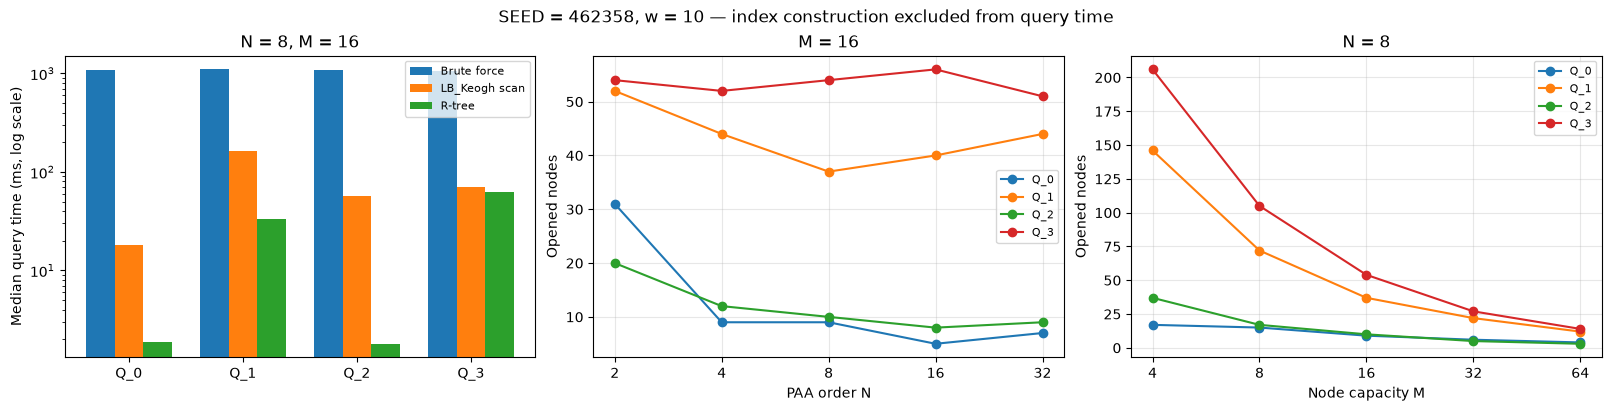

In [179]:
def brute_nn_dtw(Q, D, w):
    distances = [dtw_w(Q, T, w) for T in D]
    k = int(np.argmin(distances))
    return k, distances[k], 0, 0, len(D)


def scan_nn_dtw(Q, D, w):
    Q_envelope = envelope(Q, w)
    best_k, best_distance, n_dtw = 0, float("inf"), 0
    for k, T in enumerate(D):
        if lb_keogh(Q, T, w, Q_envelope) < best_distance:
            distance = dtw_w(Q, T, w)
            n_dtw += 1
            if distance < best_distance:
                best_k, best_distance = k, distance
    return best_k, best_distance, 0, len(D), n_dtw


# Temps médians : median_ms (T4) effectue 5 mesures après un premier appel.
methods = ["Brute force", "LB_Keogh scan", "R-tree"]
t23_times = np.zeros((4, 3))
t23_results = []
print("Query | method | time (ms) | nodes | LB_Keogh | DTW")
for j, Q in enumerate(Qs):
    searches = [lambda: brute_nn_dtw(Q, D, 10),
                lambda: scan_nn_dtw(Q, D, 10),
                lambda: rtree_nn_dtw(root, Q, D, 10, 8)]
    results = []
    for h, search in enumerate(searches):
        result = search()
        t23_times[j, h] = median_ms(search)
        results.append(result)
        print(f"Q_{j} | {methods[h]} | {t23_times[j, h]:.2f} | "
              f"{result[2]} | {result[3]} | {result[4]}")
    assert all(np.isclose(result[1], results[0][1]) for result in results)
    t23_results.append(results)

# Faire varier un paramètre à la fois ; la construction est hors chronométrage.
orders, capacities = [2, 4, 8, 16, 32], [4, 8, 16, 32, 64]
index_runs = {}
configurations = [(N, 16) for N in orders] + [(8, M) for M in capacities if M != 16]
for N, M in configurations:
    points = D.reshape(n, N, l // N).mean(axis=2)
    tree = compute_mbrs(build_rtree(D, N, M), points)
    results = [rtree_nn_dtw(tree, Q, D, 10, N) for Q in Qs]
    assert all(np.isclose(result[1], t23_results[j][0][1]) for j, result in enumerate(results))
    index_runs[N, M] = results

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for h, method in enumerate(methods):
    axes[0].bar(np.arange(4) + (h - 1) * 0.25, t23_times[:, h], width=0.25, label=method)
axes[0].set_xticks(range(4), labels=[f"Q_{j}" for j in range(4)])
axes[0].set_yscale("log")
axes[0].set_ylabel("Median query time (ms, log scale)")
axes[0].set_title("N = 8, M = 16")
axes[0].legend(fontsize=8)
for j in range(4):
    axes[1].plot(orders, [index_runs[N, 16][j][2] for N in orders], "o-", label=f"Q_{j}")
    axes[2].plot(capacities, [index_runs[8, M][j][2] for M in capacities], "o-", label=f"Q_{j}")
for ax, values, label, title in zip(
    axes[1:], [orders, capacities], ["PAA order N", "Node capacity M"], ["M = 16", "N = 8"]
):
    ax.set_xscale("log", base=2)
    ax.set_xticks(values, labels=values)
    ax.set_xlabel(label)
    ax.set_ylabel("Opened nodes")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle(f"SEED = {SEED}, w = 10 — index construction excluded from query time")
plt.show()

All three methods return the same exact neighbours. Times are medians of five runs after a warm-up, with $w=10$ and, for the index, $N=8$, $M=16$. Index construction is excluded and must be amortized across queries.

With `SEED = 462358`, brute force computes **1000 DTW distances per query**. The sequential scan computes **11, 140, 49, 60**, versus **1, 24, 1, 52** for the index. The scan may evaluate extra candidates before finding a good threshold; best-first search progressively refines the smallest lower bounds. For $Q_2$, the measured times are about **1055 ms**, **54.5 ms** and **1.8 ms**, respectively. The gain over the scan is smaller for $Q_3$ (64.5 versus 57.8 ms), where the index still computes 52 DTW distances.

Increasing **$N$** tightens the PAA bounds, but changes STR packing and MBR overlap. Node counts are not monotone: for $Q_3$, they rise from 52 at $N=4$ to 56 at $N=16$. Larger $N$ also increases the cost of each geometric bound.

Increasing **$M$** reduces visits here: for $Q_3$, from 206 at $M=4$ to 14 at $M=64$. However, each larger node contains more entries, so fewer visits do not necessarily mean a faster search.

The exact DTW counts stay unchanged across the tested index configurations. Their differences concern tree traversal and earlier filtering; the final refinements are governed by the Keogh bounds.

---
## Answers
Run this cell with **your** seed before handing in the notebook. Formats: plain numbers, or tuples `(k, distance)` for Q4/Q8, `(b_min, Err)` for Q9, `(longest, total error)` for Q10.

In [180]:
ANSWERS = {f"Q{i}": globals().get(f"Q{i}") for i in range(1, 16)}
print("SEED =", SEED)
for q, v in ANSWERS.items():
    print(q, v)

SEED = 462358
Q1 [43, 18, 14, 32]
Q2 [187.81, 108.52, 255.57, 221.03]
Q3 [158.9, 175.15, 184.21, 187.81]
Q4 [(225, 13.42), (696, 40.11), (405, 91.03), (17, 69.18)]
Q5 [55, 137, 81, 20]
Q6 [67.62, 77.92, 293.15, 1712.55]
Q7 [187.81, 178.6, 134.48, 33865.68]
Q8 [(696, 36.51), (399, 13.45), (17, 56.11), (399, 53.21)]
Q9 [(550, 42.32), (5047, 3587.2), (87825, 243740.02), (670654, 1201608.49)]
Q10 [(146, 6346.17), (1282, 208550.25), (922, 392393.34), (3116, 4959845.12)]
Q11 [2143.56, 1821.04, 9435.67, 23620.04]
Q12 [45, 25, 48, 6]
Q13 [83.82, 254.42, 208.68, 117.33]
Q14 [23, 51, 89, 124]
Q15 [9, 37, 10, 54]


### Self-check with the reference sheet (`SEED = 42` only)

In [181]:
REF42 = {
    'Q1': [27, 28, 15, 22],
    'Q2': [181.6948, 118.2159, 100.3992, 240.7011],
    'Q3': [138.3172, 165.4277, 179.1431, 181.6948],
    'Q4': [[[252], 12.8841], [[723], 40.3361], [[204], 80.8641], [[969], 75.7166]],
    'Q5': [140, 100, 50, 25],
    'Q6': [47.1275, 83.5643, 993.4667, 5869.3572],
    'Q7': [181.6948, 161.6787, 117.601, 34104.7687],
    'Q8': [[[723], 37.8682], [[194], 14.1067], [[969], 62.5859], [[8], 63.8514]],
    'Q9': [[[728, 729], 26.88], [[7549, 7550, 7551, 7552], 5316.312], [[86477, 86478, 86479, 86480, 86481], 486854.8088], [[288523], 874928.5504]],
    'Q10': [[[184], 6025.1003], [[1230], 257269.8483], [[908], 458615.382], [[2320], 4958095.1802]],
    'Q11': [673.4105, 1064.4096, 6238.0738, 18741.1973],
    'Q12': [97, 43, 57, 14],
    'Q13': [168.2914, 70.342, 285.1631, 101.2225],
    'Q14': [55, 25, 120, 31],
    'Q15': [27, 47, 19, 45],
}

def check_reference(answers=None):
    """Compares your answers with the reference sheet of the subject (only meaningful with SEED = 42)."""
    if SEED != 42:
        print("The reference sheet is for SEED = 42."); return
    answers = ANSWERS if answers is None else answers
    def close(x, y):
        return abs(float(x) - float(y)) <= max(0.011, 1e-5 * abs(float(y)))
    for q, ref in REF42.items():
        got = answers.get(q) or [None] * 4
        marks = []
        for c, r, a in zip("abcd", ref, got):
            try:
                if isinstance(r, list):          # (index or set of accepted indices, value)
                    ks, v = r
                    ok = int(a[0]) in ks and close(a[1], v)
                else:
                    ok = close(a, r)
            except Exception:
                ok = False
            marks.append(f"{c}) {'ok' if ok else '--'}")
        print(f"{q:4s}", "  ".join(marks))

check_reference()

The reference sheet is for SEED = 42.
